# XGBoost robustness check: does VIX matter?
**Claim to support:** the value of VIXCLS in Elastic Net (EN) is not a quirk of a linear model. If dropping VIX also hurts XGBoost out-of-sample, the VIX result is robust.

Per ETF (XLB, XLE, XLF, XLI, XLY), expanding window, we compare `EN` vs `EN_noVIX` and `XGB` vs `XGB_noVIX`, plus `XGB_VIXonly` vs `XGB_noMacro` (does VIX alone help?).
Evaluation: **MSE** and **QLIKE** on realised variance, then **Diebold-Mariano** tests of *noVIX vs full* within each model family.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

# ---- CONFIG ----
BASE = "/Users/lyc/Documents/GitHub/dse4101capstone-project/models/forecasting/forecasts/"
XGB_FILE = BASE + "xgb_forecasts_expanding_tidy.csv"
EN_FILE  = BASE + "en_forecasts_expanding_tidy.csv"
# label -> model name in the CSVs
MODELS = {"EN":"en_full_macro", "EN_noVIX":"en_no_vix", "EN_noMacro":"en_no_macro",
          "XGB":"xgb_full_macro", "XGB_noVIX":"xgb_no_vix", "XGB_noMacro":"xgb_no_macro", "XGB_VIXonly":"xgb_vix_only"}
# (full, restricted) pairs: positive loss diff = first one is better
PAIRS = {"EN: full vs no VIX":("EN","EN_noVIX"), "XGB: full vs no VIX":("XGB","XGB_noVIX"),
         "XGB: VIX-only vs no macro":("XGB_VIXonly","XGB_noMacro")}
HAC_LAG = 3   # Newey-West lag for DM (RV errors are persistent)

## Models used

We compare seven forecast sets, all expanding-window, per ETF (XLB, XLE, XLF, XLI, XLY), on a common sample of months.

| Label | Model name in CSV | File |
|---|---|---|
| EN | `en_full_macro` | EN |
| EN_noVIX | `en_no_vix` | EN |
| EN_noMacro | `en_no_macro` | EN |
| XGB | `xgb_full_macro` | XGB |
| XGB_noVIX | `xgb_no_vix` | XGB |
| XGB_noMacro | `xgb_no_macro` | XGB |
| XGB_VIXonly | `xgb_vix_only` | XGB |

**Excluded:** the EN models with HAR terms (`en_full_macro_har`, `en_no_macro_har`, `en_no_vix_har`) and `ols_har_no_macro`. They are not part of the VIX comparison, and the `_har` EN versions start later, which would shorten the common sample.

## Comparisons tested

| Test | Richer model | Restricted model | Question |
|---|---|---|---|
| EN: full vs no VIX | EN | EN_noVIX | Does VIX improve Elastic Net? |
| XGB: full vs no VIX | XGB | XGB_noVIX | Does VIX improve XGBoost (robustness check)? |
| XGB: VIX-only vs no macro | XGB_VIXonly | XGB_noMacro | Does VIX alone add value over no macro variables? |

Each test uses the Diebold-Mariano test (one-sided, Newey-West with 3 lags ) on MSE, log MSE and QLIKE. QLIKE is the headline loss.

In [2]:
f = pd.concat([pd.read_csv(XGB_FILE), pd.read_csv(EN_FILE)], ignore_index=True)
f["date"] = pd.to_datetime(f["date"])
f = f[f.model.isin(MODELS.values())].copy()           
f["model"] = f.model.map({v:k for k,v in MODELS.items()})
assert not f.duplicated(["model","etf","date"]).any()

wide = f.pivot(index=["date","etf"], columns="model", values="fc_level")[list(MODELS)].dropna()  # common sample
target = f.drop_duplicates(["date","etf"]).set_index(["date","etf"])["actual_RV"]
df = wide.join(target.rename("target"))

# NEW: log-scale forecasts and actuals, on the same common sample
logs = f.pivot(index=["date","etf"], columns="model", values="fc_log")[list(MODELS)].loc[df.index]
actual_log = f.drop_duplicates(["date","etf"]).set_index(["date","etf"])["actual_logRV"].loc[df.index]

chk = f.groupby(["date","etf"]).actual_RV.agg(["min","max"]); assert np.allclose(chk["min"], chk["max"], rtol=1e-6), "models disagree on actual_RV"
assert (df[list(MODELS)] > 0).all().all()
print(df.groupby("etf").size().rename("n").to_frame().T)
print("Common sample:", df.index.get_level_values(0).min().date(), "->", df.index.get_level_values(0).max().date())

etf  XLB  XLE  XLF  XLI  XLY
n    214  214  214  214  214
Common sample: 2008-02-29 -> 2025-11-30


## 1. Loss functions
- **MSE** = mean((RV − F)²). Squared error on the level, so a few high-vol months (2008, 2020) dominate.
- **QLIKE** = mean(RV/F − log(RV/F) − 1) (Patton 2011). Robust to noisy RV proxies and penalises under-prediction more than over-prediction, so it is the more reliable ranking here.
Lower is better for both.

In [3]:
def mse(y,F):   return (y-F)**2
def qlike(y,F): return y/F - np.log(y/F) - 1

L = {}
for name,fn in {"MSE":mse,"QLIKE":qlike}.items():
    L[name] = pd.DataFrame({m: fn(df.target, df[m]) for m in MODELS})

# NEW: MSE on log realised variance (the scale the models were trained on)
L["MSE_log"] = pd.DataFrame({m: (actual_log - logs[m])**2 for m in MODELS})

def summ(loss):
    per = loss.groupby(level="etf").mean()
    per.loc["ALL (avg)"] = per.mean()
    return per

for name in L: #for each loss it diplays the table of ave losses (lower better)
    t = summ(L[name])
    print(f"\n=== mean {name} ===")
    display(t.round(8) if name == "MSE" else t.round(4)) #MSE is small so 8 dec.

# loss reduction (%) from the richer model, per ETF (positive = richer model is better)
for loss in ["MSE", "MSE_log", "QLIKE"]:
    for k,(full,restr) in PAIRS.items():
        r = 1 - L[loss][full].groupby(level="etf").mean()/L[loss][restr].groupby(level="etf").mean() ## percentage improvement from VIX
        print(f"\n{loss} | {k}: relative loss reduction")
        print((100*r).round(1).astype(str)+"%")


=== mean MSE ===


,EN,EN_noVIX,EN_noMacro,XGB,XGB_noVIX,XGB_noMacro,XGB_VIXonly
etf,,,,,,,
XLB,0.000299,0.000238,0.000064,0.000076,0.000075,0.000076,0.000072
XLE,0.000235,0.000236,0.000214,0.000264,0.000262,0.000258,0.000261
XLF,0.002061,0.001541,0.000168,0.000258,0.000262,0.000207,0.000218
XLI,0.000737,0.000072,0.000054,0.000056,0.000057,0.000060,0.000056
XLY,0.002045,0.000154,0.000037,0.000049,0.000052,0.000051,0.000047
ALL (avg),0.001075,0.000448,0.000107,0.000140,0.000142,0.000130,0.000131



=== mean QLIKE ===


,EN,EN_noVIX,EN_noMacro,XGB,XGB_noVIX,XGB_noMacro,XGB_VIXonly
etf,,,,,,,
XLB,0.2795,0.3301,0.2961,0.3051,0.3421,0.3580,0.3037
XLE,0.3573,0.3697,0.2963,0.3397,0.3543,0.3423,0.3365
XLF,0.3931,0.4611,0.4043,0.4313,0.4834,0.4962,0.4283
XLI,0.3002,0.3950,0.3389,0.2971,0.3508,0.3581,0.3106
XLY,0.2933,0.3427,0.2974,0.3115,0.3561,0.3432,0.3177
ALL (avg),0.3247,0.3797,0.3266,0.3370,0.3773,0.3796,0.3394



=== mean MSE_log ===


,EN,EN_noVIX,EN_noMacro,XGB,XGB_noVIX,XGB_noMacro,XGB_VIXonly
etf,,,,,,,
XLB,0.4203,0.4790,0.4621,0.4557,0.4940,0.5455,0.4541
XLE,0.4693,0.4815,0.4523,0.4549,0.4679,0.4889,0.4798
XLF,0.6139,0.6703,0.6653,0.5952,0.6478,0.7042,0.6305
XLI,0.4554,0.5287,0.5291,0.4449,0.5135,0.5649,0.4544
XLY,0.4918,0.5258,0.5049,0.4825,0.5220,0.5355,0.5184
ALL (avg),0.4902,0.5371,0.5228,0.4866,0.5290,0.5678,0.5074



MSE | EN: full vs no VIX: relative loss reduction
etf
XLB      -25.9%
XLE        0.3%
XLF      -33.8%
XLI     -917.3%
XLY    -1224.1%
dtype: object

MSE | XGB: full vs no VIX: relative loss reduction
etf
XLB    -0.6%
XLE    -0.5%
XLF     1.9%
XLI     2.7%
XLY     5.1%
dtype: object

MSE | XGB: VIX-only vs no macro: relative loss reduction
etf
XLB     4.5%
XLE    -1.1%
XLF    -5.2%
XLI     6.8%
XLY     6.8%
dtype: object

MSE_log | EN: full vs no VIX: relative loss reduction
etf
XLB    12.3%
XLE     2.5%
XLF     8.4%
XLI    13.9%
XLY     6.5%
dtype: object

MSE_log | XGB: full vs no VIX: relative loss reduction
etf
XLB     7.8%
XLE     2.8%
XLF     8.1%
XLI    13.4%
XLY     7.6%
dtype: object

MSE_log | XGB: VIX-only vs no macro: relative loss reduction
etf
XLB    16.8%
XLE     1.9%
XLF    10.5%
XLI    19.6%
XLY     3.2%
dtype: object

QLIKE | EN: full vs no VIX: relative loss reduction
etf
XLB    15.3%
XLE     3.3%
XLF    14.7%
XLI    24.0%
XLY    14.4%
dtype: object

QLIKE | XGB: ful

## 2. Diebold-Mariano tests and Clark-West test
Loss differential `d_t = L(restricted) − L(richer)`. **Positive mean ⇒ the richer model (with VIX) is better.** H0: equal predictive accuracy; one-sided H1: the VIX model is better.
Uses a Newey-West variance and the Harvey-Leybourne-Newbold small-sample correction (t-distribution, T−1 d.o.f.).
Note: at h=1 the HAC lag is theoretically 0; we use a small positive lag as a robustness choice because RV forecast errors are autocorrelated.

In [4]:
def andrews_bandwidth(x):
    x = np.asarray(x, float); n = len(x); xd = x - x.mean()
    den = float(xd[:-1] @ xd[:-1])
    rho = 0.0 if den <= 0 else float(xd[1:] @ xd[:-1]) / den
    rho = min(max(rho, -0.97), 0.97)
    a1 = 4.0 * rho**2 / ((1 - rho)**2 * (1 + rho)**2)
    return 0 if a1 <= 0 else int(min(np.floor(1.1447 * (a1 * n) ** (1/3)), n // 4))

def newey_west_lrv(x, lag):
    x = np.asarray(x, float); n = len(x); xd = x - x.mean()
    lag = max(0, min(lag, n - 1)); s = float(xd @ xd) / n
    for l in range(1, lag + 1):
        s += 2.0 * (1.0 - l / (lag + 1.0)) * float(xd[l:] @ xd[:-l]) / n
    return max(s, 1e-16)

def hac_t(d):
    d = np.asarray(d, float)
    return d.mean() / np.sqrt(newey_west_lrv(d, andrews_bandwidth(d)) / len(d))

In [5]:
def dm_test(d, lag=None, h=1):
    d = np.asarray(d, float)
    st = hac_t(d)
    return st, 1-stats.norm.cdf(st), d.mean()
            

def star(p): return "***" if p<.01 else "**" if p<.05 else "*" if p<.10 else ""

rows=[]
for loss in L:
    for k,(full,restr) in PAIRS.items():
        d_all = L[loss][restr] - L[loss][full]
        groups = {e:g.values for e,g in d_all.groupby(level="etf")}
        groups["ALL (avg across ETFs)"] = d_all.groupby(level="date").mean().values
        for e,d in groups.items():
            st,p,m = dm_test(d)
            rows.append(dict(loss=loss, family=k, etf=e, mean_diff=m, DM=st, p_one_sided=p, sig=star(p)))
dm = pd.DataFrame(rows)
display(dm.pivot_table(index="etf", columns=["loss","family"], values="DM").round(2))
display(dm.pivot_table(index="etf", columns=["loss","family"], values="p_one_sided").round(3))
dm.to_csv("dm_vix_robustness.csv", index=False)

loss                                 MSE                            \
family                EN: full vs no VIX XGB: VIX-only vs no macro   
etf                                                                  
ALL (avg across ETFs)              -0.91                     -0.13   
XLB                                -1.13                      1.17   
XLE                                 0.35                     -0.33   
XLF                                -0.62                     -0.69   
XLI                                -1.02                      1.51   
XLY                                -0.99                      1.54   

loss                                                 MSE_log  \
family                XGB: full vs no VIX EN: full vs no VIX   
etf                                                            
ALL (avg across ETFs)                0.38               2.55   
XLB                                 -0.27               3.08   
XLE                                 -0.18               2.38   
XLF                                  0.36               2.05   
XLI                                  0.83               2.08   
XLY                                  1.24               1.32   

loss                                                                 \
family                XGB: VIX-only vs no macro XGB: full vs no VIX   
etf                                                                   
ALL (avg across ETFs)                      3.84                2.54   
XLB                                        4.11                1.82   
XLE                                        0.60                1.15   
XLF                                        2.71                2.07   
XLI                                        4.38                2.58   
XLY                                        0.64                1.86   

loss                               QLIKE                            \
family                EN: full vs no VIX XGB: VIX-only vs no macro   
etf                                                                  
ALL (avg across ETFs)               1.44                      1.86   
XLB                                 1.79                      2.64   
XLE                                 1.42                      0.53   
XLF                                 0.96                      1.41   
XLI                                 1.53                      2.55   
XLY                                 1.77                      0.84   

loss                                       
family                XGB: full vs no VIX  
etf                                        
ALL (avg across ETFs)                1.58  
XLB                                  1.39  
XLE                                  1.22  
XLF                                  1.40  
XLI                                  1.47  
XLY                                  1.80

loss                                 MSE                            \
family                EN: full vs no VIX XGB: VIX-only vs no macro   
etf                                                                  
ALL (avg across ETFs)              0.818                     0.551   
XLB                                0.872                     0.122   
XLE                                0.363                     0.630   
XLF                                0.732                     0.754   
XLI                                0.846                     0.066   
XLY                                0.839                     0.061   

loss                                                 MSE_log  \
family                XGB: full vs no VIX EN: full vs no VIX   
etf                                                            
ALL (avg across ETFs)               0.352              0.005   
XLB                                 0.606              0.001   
XLE                                 0.572              0.009   
XLF                                 0.361              0.020   
XLI                                 0.202              0.019   
XLY                                 0.108              0.093   

loss                                                                 \
family                XGB: VIX-only vs no macro XGB: full vs no VIX   
etf                                                                   
ALL (avg across ETFs)                     0.000               0.006   
XLB                                       0.000               0.034   
XLE                                       0.275               0.124   
XLF                                       0.003               0.019   
XLI                                       0.000               0.005   
XLY                                       0.260               0.031   

loss                               QLIKE                            \
family                EN: full vs no VIX XGB: VIX-only vs no macro   
etf                                                                  
ALL (avg across ETFs)              0.076                     0.031   
XLB                                0.037                     0.004   
XLE                                0.078                     0.297   
XLF                                0.168                     0.079   
XLI                                0.063                     0.005   
XLY                                0.039                     0.201   

loss                                       
family                XGB: full vs no VIX  
etf                                        
ALL (avg across ETFs)               0.057  
XLB                                 0.082  
XLE                                 0.112  
XLF                                 0.081  
XLI                                 0.071  
XLY                                 0.036

In [6]:
# XGBoost vs Elastic Net, matched on the same inputs
CROSS = {"Full macro: XGB vs EN": ("XGB", "EN"),
         "No VIX: XGB vs EN":     ("XGB_noVIX", "EN_noVIX"),
         "No macro: XGB vs EN":   ("XGB_noMacro", "EN_noMacro")}

rows = []
for loss in L:
    for k,(xgb,en) in CROSS.items():
        d_all = L[loss][en] - L[loss][xgb]          # positive = XGBoost better
        groups = {e:g.values for e,g in d_all.groupby(level="etf")}
        groups["ALL (avg across ETFs)"] = d_all.groupby(level="date").mean().values
        for e,d in groups.items():
            st,_,m = dm_test(d)
            p2 = 2*(1 - stats.norm.cdf(abs(st))) if not np.isnan(st) else np.nan   # two-sided
            rows.append(dict(loss=loss, comparison=k, etf=e, mean_diff=m, DM=st, p_two_sided=p2, sig=star(p2/2)))
dm_x = pd.DataFrame(rows)
display(dm_x.pivot_table(index="etf", columns=["loss","comparison"], values="DM").round(2))
display(dm_x.pivot_table(index="etf", columns=["loss","comparison"], values="p_two_sided").round(3))
dm_x.to_csv("dm_xgb_vs_en.csv", index=False)

loss                                    MSE                    \
comparison            Full macro: XGB vs EN No VIX: XGB vs EN   
etf                                                             
ALL (avg across ETFs)                  1.17              1.46   
XLB                                    1.05              1.01   
XLE                                   -1.38             -1.29   
XLF                                    1.45              1.62   
XLI                                    1.02              0.91   
XLY                                    1.02              1.03   

loss                                                    MSE_log  \
comparison            No macro: XGB vs EN Full macro: XGB vs EN   
etf                                                               
ALL (avg across ETFs)               -1.92                  0.14   
XLB                                 -2.55                 -1.33   
XLE                                 -1.53                  0.49   
XLF                                 -1.14                  0.45   
XLI                                 -1.45                  0.26   
XLY                                 -1.77                  0.25   

loss                                                         \
comparison            No VIX: XGB vs EN No macro: XGB vs EN   
etf                                                           
ALL (avg across ETFs)              0.38               -1.86   
XLB                               -0.51               -2.82   
XLE                                0.52               -1.26   
XLF                                0.57               -0.72   
XLI                                0.52               -0.99   
XLY                                0.13               -1.10   

loss                                  QLIKE                    \
comparison            Full macro: XGB vs EN No VIX: XGB vs EN   
etf                                                             
ALL (avg across ETFs)                 -0.49              0.11   
XLB                                   -1.18             -0.41   
XLE                                    0.44              0.45   
XLF                                   -0.50             -0.48   
XLI                                    0.17              1.14   
XLY                                   -1.15             -0.50   

loss                                       
comparison            No macro: XGB vs EN  
etf                                        
ALL (avg across ETFs)               -1.46  
XLB                                 -2.27  
XLE                                 -1.63  
XLF                                 -0.86  
XLI                                 -0.87  
XLY                                 -1.75

loss                                    MSE                    \
comparison            Full macro: XGB vs EN No VIX: XGB vs EN   
etf                                                             
ALL (avg across ETFs)                 0.242             0.145   
XLB                                   0.293             0.315   
XLE                                   0.168             0.199   
XLF                                   0.147             0.105   
XLI                                   0.306             0.363   
XLY                                   0.310             0.303   

loss                                                    MSE_log  \
comparison            No macro: XGB vs EN Full macro: XGB vs EN   
etf                                                               
ALL (avg across ETFs)               0.054                 0.889   
XLB                                 0.011                 0.185   
XLE                                 0.127                 0.627   
XLF                                 0.255                 0.649   
XLI                                 0.146                 0.794   
XLY                                 0.077                 0.803   

loss                                                         \
comparison            No VIX: XGB vs EN No macro: XGB vs EN   
etf                                                           
ALL (avg across ETFs)             0.705               0.063   
XLB                               0.610               0.005   
XLE                               0.601               0.209   
XLF                               0.569               0.473   
XLI                               0.603               0.320   
XLY                               0.896               0.271   

loss                                  QLIKE                    \
comparison            Full macro: XGB vs EN No VIX: XGB vs EN   
etf                                                             
ALL (avg across ETFs)                 0.623             0.911   
XLB                                   0.236             0.681   
XLE                                   0.660             0.652   
XLF                                   0.617             0.628   
XLI                                   0.863             0.253   
XLY                                   0.248             0.616   

loss                                       
comparison            No macro: XGB vs EN  
etf                                        
ALL (avg across ETFs)               0.145  
XLB                                 0.023  
XLE                                 0.103  
XLF                                 0.392  
XLI                                 0.384  
XLY                                 0.081

In [7]:
# Clark-West test for nested models: H1 = the richer model (with VIX) forecasts better
def cw_series(y, F_restr, F_full):
    # adjusted loss differential: restricted loss minus (full loss minus the noise adjustment)
    return (y - F_restr)**2 - ((y - F_full)**2 - (F_restr - F_full)**2)

CW_DATA = {"MSE":     (df.target, df),      # level variance
           "MSE_log": (actual_log, logs)}   # log variance

rows = []
for loss,(y,F) in CW_DATA.items():
    for k,(full,restr) in PAIRS.items():
        f_all = cw_series(y, F[restr], F[full])
        groups = {e:g.values for e,g in f_all.groupby(level="etf")}
        groups["ALL (avg across ETFs)"] = f_all.groupby(level="date").mean().values
        for e,f_ in groups.items():
            st,p,m = dm_test(f_)        # tests mean(f_) > 0 with Newey-West variance
            rows.append(dict(loss=loss, family=k, etf=e, CW=st, p_one_sided=p, sig=star(p)))
cw = pd.DataFrame(rows)
display(cw.pivot_table(index="etf", columns=["loss","family"], values="CW").round(2))
display(cw.pivot_table(index="etf", columns=["loss","family"], values="p_one_sided").round(3))
cw.to_csv("clark_west_vix.csv", index=False)

loss                                 MSE                            \
family                EN: full vs no VIX XGB: VIX-only vs no macro   
etf                                                                  
ALL (avg across ETFs)              -0.54                      1.57   
XLB                                -0.64                      2.22   
XLE                                 0.71                      0.43   
XLF                                 0.34                     -0.11   
XLI                                -0.98                      2.21   
XLY                                -0.96                      2.35   

loss                                                 MSE_log  \
family                XGB: full vs no VIX EN: full vs no VIX   
etf                                                            
ALL (avg across ETFs)                1.29               4.78   
XLB                                  0.89               4.90   
XLE                                  0.61               2.65   
XLF                                  0.86               3.68   
XLI                                  1.74               4.63   
XLY                                  1.88               4.52   

loss                                                                 
family                XGB: VIX-only vs no macro XGB: full vs no VIX  
etf                                                                  
ALL (avg across ETFs)                      6.45                4.21  
XLB                                        6.21                3.61  
XLE                                        1.73                2.14  
XLF                                        4.46                3.45  
XLI                                        6.16                4.12  
XLY                                        2.69                3.64

loss                                 MSE                            \
family                EN: full vs no VIX XGB: VIX-only vs no macro   
etf                                                                  
ALL (avg across ETFs)              0.704                     0.058   
XLB                                0.739                     0.013   
XLE                                0.239                     0.335   
XLF                                0.365                     0.544   
XLI                                0.836                     0.013   
XLY                                0.831                     0.009   

loss                                                 MSE_log  \
family                XGB: full vs no VIX EN: full vs no VIX   
etf                                                            
ALL (avg across ETFs)               0.098              0.000   
XLB                                 0.188              0.000   
XLE                                 0.271              0.004   
XLF                                 0.195              0.000   
XLI                                 0.041              0.000   
XLY                                 0.030              0.000   

loss                                                                 
family                XGB: VIX-only vs no macro XGB: full vs no VIX  
etf                                                                  
ALL (avg across ETFs)                     0.000               0.000  
XLB                                       0.000               0.000  
XLE                                       0.042               0.016  
XLF                                       0.000               0.000  
XLI                                       0.000               0.000  
XLY                                       0.004               0.000

In [8]:
LOSS_MAP = {"QLIKE": "QLIKE", "MSE_log": "MSE_log", "MSE": "MSE_level"}

parts = []
for m, name in MODELS.items():
    t = pd.DataFrame({new: L[old][m] for old, new in LOSS_MAP.items()})
    g = t.groupby(level="etf").mean().reset_index().rename(columns={"etf": "ETF"})
    g = pd.concat([g, t.mean().to_frame().T.assign(ETF="pooled")], ignore_index=True)
    g.insert(0, "model", name); parts.append(g)
vix_losses = pd.concat(parts, ignore_index=True)
vix_losses.to_csv("xgb_vix_losses.csv", index=False)

li = vix_losses.set_index(["model", "ETF"])
etfs = sorted(df.index.get_level_values("etf").unique())
rows = []
for i, (k, (a, b)) in enumerate(PAIRS.items(), 1):
    cw_t_all = cw_series(actual_log, logs[b], logs[a])      # Clark-West; positive favours a
    dm_t_all = L["QLIKE"][b] - L["QLIKE"][a]                # positive favours a
    for etf in ["pooled"] + etfs:
        if etf == "pooled": cw_x, dm_x_ = cw_t_all.groupby(level="date").mean(), dm_t_all.groupby(level="date").mean()
        else:               cw_x, dm_x_ = cw_t_all.xs(etf, level="etf"), dm_t_all.xs(etf, level="etf")
        for loss, test, x in [("QLIKE", "DM", dm_x_), ("MSE_log", "Clark-West", cw_x)]:
            t_ = hac_t(x)
            rows.append({"pair": f"P{i}", "a": MODELS[a], "b": MODELS[b], "ETF": etf, "loss": loss, "test": test,
                         "loss_ratio": li.loc[(MODELS[a], etf), loss] / li.loc[(MODELS[b], etf), loss],
                         "gain_t": t_, "p_value": float(1 - stats.norm.cdf(t_))})
vix_tests = pd.DataFrame(rows)
vix_tests.to_csv("xgb_vix_tests.csv", index=False)

def fmt_p(p): return "<0.001" if p < 0.001 else f"{p:.3f}"
print("Pooled (Clark-West on log MSE = primary; QLIKE = supporting):")
display(vix_tests[vix_tests.ETF == "pooled"].drop(columns="ETF").round(4).reset_index(drop=True))

for loss, test in [("MSE_log", "Clark-West"), ("QLIKE", "DM")]:
    s = vix_tests[vix_tests.loss == loss].copy()
    s["cell"] = [f"{r:.2f} ({fmt_p(p)})" for r, p in zip(s.loss_ratio, s.p_value)]
    s["row"] = s.pair + ": " + s.a + " vs " + s.b
    print(f"\n{loss}: loss ratio (one-sided p), {test}")
    display(s.pivot(index="row", columns="ETF", values="cell")[etfs + ["pooled"]].rename_axis(None))

Pooled (Clark-West on log MSE = primary; QLIKE = supporting):


,pair,a,b,loss,test,loss_ratio,gain_t,p_value
0,P1,en_full_macro,en_no_vix,QLIKE,DM,0.8551,1.4351,0.0756
1,P1,en_full_macro,en_no_vix,MSE_log,Clark-West,0.9126,4.7792,0.0000
2,P2,xgb_full_macro,xgb_no_vix,QLIKE,DM,0.8930,1.5833,0.0567
3,P2,xgb_full_macro,xgb_no_vix,MSE_log,Clark-West,0.9198,4.2115,0.0000
4,P3,xgb_vix_only,xgb_no_macro,QLIKE,DM,0.8941,1.8605,0.0314
5,P3,xgb_vix_only,xgb_no_macro,MSE_log,Clark-West,0.8936,6.4529,0.0000



MSE_log: loss ratio (one-sided p), Clark-West


ETF,XLB,XLE,XLF,XLI,XLY,pooled
P1: en_full_macro vs en_no_vix,0.88 (<0.001),0.97 (0.004),0.92 (<0.001),0.86 (<0.001),0.94 (<0.001),0.91 (<0.001)
P2: xgb_full_macro vs xgb_no_vix,0.92 (<0.001),0.97 (0.016),0.92 (<0.001),0.87 (<0.001),0.92 (<0.001),0.92 (<0.001)
P3: xgb_vix_only vs xgb_no_macro,0.83 (<0.001),0.98 (0.042),0.90 (<0.001),0.80 (<0.001),0.97 (0.004),0.89 (<0.001)



QLIKE: loss ratio (one-sided p), DM


ETF,XLB,XLE,XLF,XLI,XLY,pooled
P1: en_full_macro vs en_no_vix,0.85 (0.037),0.97 (0.078),0.85 (0.168),0.76 (0.063),0.86 (0.039),0.86 (0.076)
P2: xgb_full_macro vs xgb_no_vix,0.89 (0.082),0.96 (0.112),0.89 (0.081),0.85 (0.071),0.87 (0.036),0.89 (0.057)
P3: xgb_vix_only vs xgb_no_macro,0.85 (0.004),0.98 (0.297),0.86 (0.079),0.87 (0.005),0.93 (0.201),0.89 (0.031)


## 3. Cumulative loss differential (does the VIX gain build up steadily or come from a few episodes?)

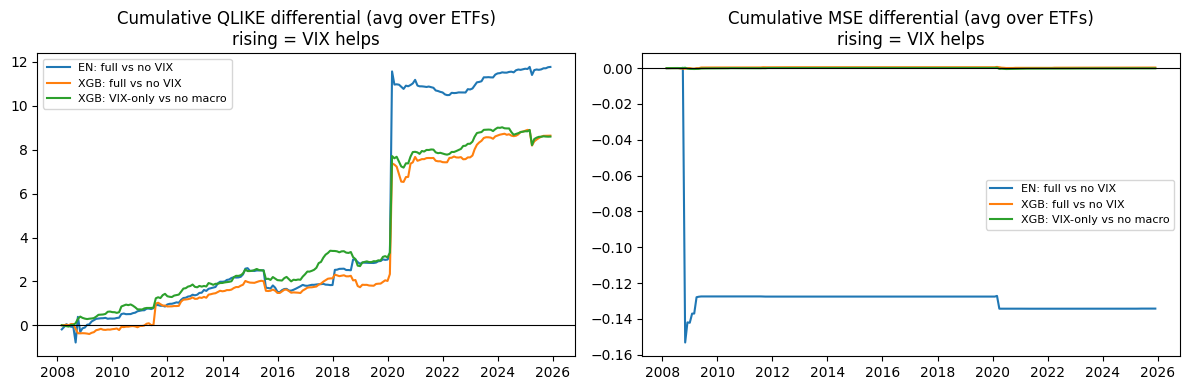

In [9]:
fig, ax = plt.subplots(1,2, figsize=(12,4), sharex=True)
for a,loss in zip(ax,["QLIKE","MSE"]):
    for k,(full,restr) in PAIRS.items():
        d = (L[loss][restr]-L[loss][full]).groupby(level="date").mean()
        a.plot(d.cumsum(), label=k)
    a.axhline(0,color="k",lw=.8); a.set_title(f"Cumulative {loss} differential (avg over ETFs)\nrising = VIX helps"); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig("vix_cum_loss_diff.png", dpi=150); plt.show()

## 4. Results interpretation (auto-generated from the numbers above)

In [10]:
def verdict(k, loss):
    r = dm[(dm.loss==loss)&(dm.family==k)]
    allrow = r[r.etf.str.startswith("ALL")].iloc[0]
    e = r[~r.etf.str.startswith("ALL")]
    return allrow, (e.mean_diff>0).sum(), (e.p_one_sided<.10).sum(), len(e)

for loss in ["QLIKE","MSE"]:
    for k in PAIRS:
        a,npos,nsig,n = verdict(k,loss)
        direction = "improves" if a.mean_diff>0 else "does NOT improve"
        print(f"- {loss} | {k}: VIX {direction} accuracy on average (DM={a.DM:.2f}, one-sided p={a.p_one_sided:.3f}{a.sig}); "
              f"better in {npos}/{n} ETFs, significantly (10%) in {nsig}/{n}.")

p = vix_tests[(vix_tests.ETF=="pooled") & (vix_tests.loss=="MSE_log")].set_index("a")["p_value"]
ok = p["en_full_macro"] < .05 and p["xgb_full_macro"] < .05
print("\nCONCLUSION (Clark-West on log MSE):",
      "XGBoost corroborates EN: VIX adds significant out-of-sample value in both model families (robust)." if ok else
      "Evidence is not significant in at least one family: report as supportive, not conclusive.")

- QLIKE | EN: full vs no VIX: VIX improves accuracy on average (DM=1.44, one-sided p=0.076*); better in 5/5 ETFs, significantly (10%) in 4/5.
- QLIKE | XGB: full vs no VIX: VIX improves accuracy on average (DM=1.58, one-sided p=0.057*); better in 5/5 ETFs, significantly (10%) in 4/5.
- QLIKE | XGB: VIX-only vs no macro: VIX improves accuracy on average (DM=1.86, one-sided p=0.031**); better in 5/5 ETFs, significantly (10%) in 3/5.
- MSE | EN: full vs no VIX: VIX does NOT improve accuracy on average (DM=-0.91, one-sided p=0.818); better in 1/5 ETFs, significantly (10%) in 0/5.
- MSE | XGB: full vs no VIX: VIX improves accuracy on average (DM=0.38, one-sided p=0.352); better in 3/5 ETFs, significantly (10%) in 0/5.
- MSE | XGB: VIX-only vs no macro: VIX does NOT improve accuracy on average (DM=-0.13, one-sided p=0.551); better in 3/5 ETFs, significantly (10%) in 2/5.

CONCLUSION (Clark-West on log MSE): XGBoost corroborates EN: VIX adds significant out-of-sample value in both model famil

## How to read the tables
The XGBoost vs Elastic Net table uses Diebold-Mariano tests, which are valid here because the two models are not nested. A positive statistic means XGBoost is better and a negative one means EN is better. p-values are two-sided. In each column both models use the same inputs (full macro, no VIX, lags only).

1. Full macro and no VIX: no detectable difference
- The pooled statistics are small: 0.14 (log MSE) and −0.49 (QLIKE) for full macro, and 0.38 and 0.11 for no VIX. The p-values are between 0.62 and 0.91, so nothing is significant.
- The sign changes across ETFs and losses. For example, XLB is negative on log MSE (−1.33, p = 0.185) while the other four ETFs are positive.
- Conclusion: once macro information is available, the two models cannot be told apart on these tests.

2. No macro (lags only): EN is modestly ahead
- The pooled statistics are −1.86 on log MSE (p = 0.063) and −1.46 on QLIKE (p = 0.145).
- The sign is negative in all five ETFs on both losses, which is unlikely if the models were truly equal. Significance comes mainly from XLB (p = 0.005 on log MSE and 0.023 on QLIKE), with XLY borderline on QLIKE (p = 0.081).
- Conclusion: with only lagged variance as input, EN is modestly better than XGBoost, although the pooled result is borderline.

3. The pattern across the three columns
- XGBoost goes from behind EN with no macro inputs to level with it once macro variables are added.
- A reasonable reading is that XGBoost gains more from macro inputs than EN does. That is an interpretation, not something these tests prove.

What to be careful about
- A p-value above 0.10 means the models cannot be told apart, which is different from showing they are equal. With about 214 months per ETF, power is limited.
- Per-ETF results are noisy, so rely on the pooled row and on how consistent the signs are.
- Level MSE is not tested, because single extreme forecasts (such as EN's in 2009) dominate it.

Clark-West table, which corrects for the models being nested. The top table is the CW statistic and the bottom one is the one-sided p-value for “adding VIX helps”.

Log MSE: strong evidence

The pooled statistics are 4.78 for EN, 6.45 for XGBoost with only VIX versus no macro, and 4.21 for XGBoost full, all with p = 0.000.
The result is broad. Every ETF is significant at 5% or better, including XLE for XGBoost with only VIX versus no macro (p = 0.042, the largest p-value in the table). XLE is the weakest ETF in all three comparisons, but even there the effect is positive (statistics 2.65 for EN, 2.14 for full XGBoost and 1.73 for VIX-only XGBoost).
The effect is large relative to DM. For EN, CW gives 4.78 where DM gave about 2.5, which is the nested-model correction doing its job.

Level MSE: mixed
For XGBoost, the evidence is moderate. Pooled p = 0.058 for VIX-only versus no macro, and 0.098 for XGBoost full. It is significant in XLB, XLI and XLY for the VIX-only comparison (p = 0.013, 0.013, 0.009) but not in XLE (0.335) or XLF (0.544).
For EN, there is no evidence (−0.54, p = 0.70, and no ETF is significant). This is the loss distorted by EN’s single bad 2009 forecast, so the lack of significance doesn’t mean VIX is useless in EN.
XLF is the one ETF where level MSE gives no support for VIX in XGBoost.

What this adds
On log MSE, the strongest loss for our claim, VIX helps in both models, in every ETF, with very small p-values.
The results line up with QLIKE in direction (loss ratios of 0.86 for EN and 0.89 for both XGBoost comparisons, with DM p-values of 0.076, 0.057 and 0.031 as supporting evidence), which makes the conclusion more reliable.
Level MSE is the weak spot, mainly because of outliers, so treat it as a robustness check and say so.

For the report: Clark-West tests show that including VIX significantly improves log-variance forecasts for Elastic Net (CW = 4.78), XGBoost (4.21) and VIX-only XGBoost against a no-macro model (6.45), all with p < 0.001, and in every ETF. Results on level MSE are weaker (borderline for XGBoost, not significant for EN).

Cumulative Loss differentials
Each chart tracks the running total of the monthly loss gap between the model without VIX and the same model with VIX, averaged across the five ETFs. A line that rises means VIX is helping. A flat line means no difference. A line that falls means VIX made things worse. The three lines are EN full vs no VIX, XGBoost full vs no VIX, and XGBoost with only VIX vs no macro.

Left chart (QLIKE)
All three lines end well above zero (about 12 for EN and about 8.5 for the XGBoost lines). Over the whole 2008 to 2025 sample, VIX reduced QLIKE loss for every model.
Before 2020, the lines climb slowly and steadily, so VIX helped a little in many months.
In early 2020 there is a sharp vertical jump in all three lines. For EN, the jump is about 10 units and accounts for most of the total gain. This is the COVID volatility spike, when VIX reacted immediately and the models without it were slow. So much of VIX’s benefit comes from a few extreme months.
After 2020, the lines drift up gently for EN and flatten for XGBoost.
The EN line starts roughly level with the XGBoost lines but pulls ahead. EN gained the most from VIX in QLIKE terms, mostly through that 2020 jump.

Right chart (MSE)
The XGBoost lines sit at about zero throughout, because the squared errors on this scale are tiny.
The EN line makes one sharp drop around 2008 to 2009 to about −0.15 and then stays flat. That is the single bad EN forecast I mentioned. In that month the EN model with VIX produced a very poor forecast, which creates a large loss difference that is never recovered.
This one month is why EN looked insignificant or negative on level MSE, even though it gains on log MSE and QLIKE. It also explains why level MSE is the least reliable of the three losses.

What to say in the write-up: VIX improves forecasts across the sample on QLIKE, but a large share of the gain comes from the 2020 volatility spike, and the level MSE comparison for EN is dominated by one forecast in 2008 to 2009.